<a href="https://colab.research.google.com/github/sigvehaug/MLwPython/blob/master/1_ML_Concepts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Load, transform and explore line profile data

Basic machine learning using clusting methods with Python.

Simon Schüpbach, 2026. https://github.com/SimonSchuepbach/CAS-ADS-2026-Projects.git



### Main Goals in that Notebook

- Load passenger data from PostAuto, aggregated by line, weekdaytype and hour
- Transform the data set to be processed using the methods we learned in module 3
- Do some exploratory work on the data set (PCA,...)
- Cluster the lines based on the iimported data set (commuter, touristic,...)

# Table of Content


1. Libraties
2. Load and transform the data set
3. PCA
4. Clustering using UMAP


## 1. Load the libraries

In [1]:
from pathlib import Path
from matplotlib import pyplot as plt # samesame import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
import umap
from sklearn.manifold import TSNE
import hdbscan
from sklearn.preprocessing import MinMaxScaler

## 2. Load and inspect the line profiles dataset (exploratory data analysis)

In [ ]:
data_path = Path("..") / ".." / "data" / "afz_line_profiles_202602-202608.csv"
line_profiles_raw = pd.read_csv(data_path)

line_profiles_raw.head(5)

For each line number there's the sum of the number of passengers for each weekday and hour, as well as an indicator, how many times this time slot is present in the data set. Based on that information, the **mean of passengers is calculated per weekdaytype (either "Mon-Fri" or "Sat-Sun")** and hour.

In [8]:
line_profiles = (
    line_profiles_raw
    .drop(columns=["weekday", "departurecet_hhmm"])
    .fillna(0)
    .assign(
        weekday_group=np.where(
            line_profiles_raw["weekday_nr"].between(1, 5),
            "Mon-Fri",
            "Sat-Sun",
        )
    )
    .groupby(
        ["systemlinenumber", "weekday_group", "departurecet_h"],
        as_index=False,
    )
    .agg(
        boarding_per_hour=("boarding_per_hour", "sum"),
        ndays=("ndays", "sum"),
    )
)

line_profiles["weekday_nr"] = line_profiles["weekday_group"].map(
    {"Mon-Fri": 0, "Sat-Sun": 1}
)

line_profiles["mean_boarding_per_hour"] = (
    line_profiles["boarding_per_hour"]
    / line_profiles["ndays"]
).fillna(0)

line_profiles.head()

,systemlinenumber,weekday_group,departurecet_h,boarding_per_hour,ndays,weekday_nr,mean_boarding_per_hour
0,11,Mon-Fri,0,794,112.0,0,7.089286
1,11,Mon-Fri,1,199,24.0,0,8.291667
2,11,Mon-Fri,2,17,24.0,0,0.708333
3,11,Mon-Fri,3,0,0.0,0,0.000000
4,11,Mon-Fri,4,0,0.0,0,0.000000


In [9]:
line_profiles.info()

<class 'pandas.DataFrame'>
RangeIndex: 45840 entries, 0 to 45839
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   systemlinenumber        45840 non-null  int64  
 1   weekday_group           45840 non-null  str    
 2   departurecet_h          45840 non-null  int64  
 3   boarding_per_hour       45840 non-null  int64  
 4   ndays                   45840 non-null  float64
 5   weekday_nr              45840 non-null  int64  
 6   mean_boarding_per_hour  45840 non-null  float64
dtypes: float64(2), int64(4), str(1)
memory usage: 2.4 MB


The passenger numbers are now **normalized** by systemlinenumber, in order not to have the absolute number of passengers as a dominant component in the data set, since here we are interested in the profiles/ daily shapes of the passengers per lines.

Additionally, the **ratio of the total boardings per weekend to those of the workdays** (per day) is calculated. This feature results from module 2. It is later on joined to the wide table as an additional feature by systemlinenumber.

Further artificial features are introduced, such as typical ratios (e.g. weekday at 17 vs weekend at 17).

In [17]:
line_profiles["normalized_boarding"] = (
    line_profiles["mean_boarding_per_hour"]
    / line_profiles.groupby("systemlinenumber")["mean_boarding_per_hour"]
        .transform("max")
)

# Average daily boardings by weekday type
line_profiles["boarding_per_weekdaytype"] = (
    line_profiles.groupby(["systemlinenumber", "weekday_group"])["mean_boarding_per_hour"].transform("sum")
    / line_profiles["weekday_group"].map({"Mon-Fri": 5, "Sat-Sun": 2})
)
boarding_ratio = (
    line_profiles
    .groupby(["systemlinenumber", "weekday_group"])["boarding_per_weekdaytype"]
    .first()
    .unstack("weekday_group")
    .assign(
        weekend_to_workday_ratio=lambda df:
            df["Sat-Sun"].div(df["Mon-Fri"].where(df["Mon-Fri"].ne(0)))
    )
    .reset_index()[["systemlinenumber", "weekend_to_workday_ratio"]]
)
boarding_ratio["weekend_to_workday_ratio"] = (
    boarding_ratio["weekend_to_workday_ratio"].fillna(0)
)
boarding_ratio["weekend_to_workday_ratio"] = MinMaxScaler().fit_transform(
    boarding_ratio[["weekend_to_workday_ratio"]]
).ravel()

The data set is further reformatted, in order to have each line on one row (since each line corresponds to one observation). To get there, the **number of passengers** per weekdaytype and hour **are converted to features of each line** by pivoting the data frame (from a long to a wide table).

In [18]:
line_profiles_wide = (
    line_profiles
    .pivot_table(
        index="systemlinenumber",
        columns=["weekday_nr", "departurecet_h"],
        values="normalized_boarding",
        aggfunc="mean",
    )
    # .round()
    # .astype("int64")
)

line_profiles_wide.columns = [
    f"weekdaytype_{weekday}_hour_{hour}"
    for weekday, hour in line_profiles_wide.columns.to_flat_index()
]

line_profiles_wide = line_profiles_wide.reset_index()

# add additional columns that represent obious features of the line profiles, in order to improve clustering 
for hour in (8, 17):
    numerator = line_profiles_wide[f"weekdaytype_0_hour_{hour}"]
    denominator = line_profiles_wide[f"weekdaytype_1_hour_{hour}"]
    line_profiles_wide[f"weekdaytype_ratio_hour_{hour}"] = (
        numerator.div(denominator.where(denominator.ne(0))).fillna(0)
    )

# and also scale the ratio columns to a range between 0 and 1, in order to avoid that they dominate the clustering due to their potentially large values
ratio_columns = [
    "weekdaytype_ratio_hour_8",
    "weekdaytype_ratio_hour_17",
]

line_profiles_wide[ratio_columns] = MinMaxScaler().fit_transform(
    line_profiles_wide[ratio_columns]
)

# here the boarding ratio is merged into the line_profiles_wide dataframe, so that it can be used as an additional feature for clustering
line_profiles_wide = line_profiles_wide.merge(
    boarding_ratio,
    on="systemlinenumber",
    how="left",
)

line_profiles_wide.head()

,systemlinenumber,weekdaytype_0_hour_0,weekdaytype_0_hour_1,weekdaytype_0_hour_2,weekdaytype_0_hour_3,weekdaytype_0_hour_4,weekdaytype_0_hour_5,weekdaytype_0_hour_6,weekdaytype_0_hour_7,weekdaytype_0_hour_8,...,weekdaytype_1_hour_17,weekdaytype_1_hour_18,weekdaytype_1_hour_19,weekdaytype_1_hour_20,weekdaytype_1_hour_21,weekdaytype_1_hour_22,weekdaytype_1_hour_23,weekdaytype_ratio_hour_8,weekdaytype_ratio_hour_17,weekend_to_workday_ratio
0,11,0.067256,0.078663,0.006720,0.0,0.0,0.030358,0.270415,1.000000,0.612720,...,0.297101,0.305639,0.187684,0.171240,0.084276,0.117245,0.028103,0.019242,0.007185,0.002657
1,20,0.060927,0.016274,0.000439,0.0,0.0,0.059279,0.256136,1.000000,0.392558,...,0.180437,0.173671,0.151253,0.048223,0.092867,0.078071,0.018077,0.024572,0.008040,0.001850
2,30,0.000000,0.000000,0.000000,0.0,0.0,0.058371,0.252982,1.000000,0.646558,...,0.301287,0.314908,0.243729,0.185287,0.156229,0.177454,0.000000,0.022284,0.008898,0.002308
3,31,0.000000,0.000000,0.000000,0.0,0.0,0.071100,0.464321,1.000000,0.366864,...,0.149649,0.140675,0.087571,0.000000,0.000000,0.000000,0.000000,0.017712,0.005411,0.001356
4,32,0.000000,0.000000,0.054751,0.0,0.0,0.048356,0.325576,0.750296,0.827541,...,0.226144,0.220690,0.199632,0.129719,0.101501,0.093639,0.000000,0.053722,0.008433,0.001509


In [13]:
line_profiles_wide.describe()

,systemlinenumber,weekdaytype_0_hour_0,weekdaytype_0_hour_1,weekdaytype_0_hour_2,weekdaytype_0_hour_3,weekdaytype_0_hour_4,weekdaytype_0_hour_5,weekdaytype_0_hour_6,weekdaytype_0_hour_7,weekdaytype_0_hour_8,...,weekdaytype_1_hour_17,weekdaytype_1_hour_18,weekdaytype_1_hour_19,weekdaytype_1_hour_20,weekdaytype_1_hour_21,weekdaytype_1_hour_22,weekdaytype_1_hour_23,weekdaytype_ratio_hour_8,weekdaytype_ratio_hour_17,weekend_to_workday_ratio
count,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,...,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000,950.000000
mean,2147.341053,0.041964,0.039909,0.033179,0.018028,0.010827,0.053586,0.277402,0.551273,0.315844,...,0.264342,0.191690,0.139087,0.103818,0.094809,0.083821,0.074798,0.009046,0.005446,2.713622
std,1524.704154,0.135474,0.144554,0.124690,0.078404,0.076646,0.097149,0.299754,0.428813,0.281502,...,0.263547,0.216980,0.189246,0.159248,0.181631,0.175419,0.170832,0.035143,0.039561,17.336452
min,11.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,866.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.473520
50%,2020.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.193196,0.707791,0.333844,...,0.228539,0.125415,0.013602,0.000000,0.000000,0.000000,0.000000,0.004693,0.002809,1.349986
75%,3003.750000,0.004219,0.000000,0.000000,0.000000,0.000000,0.076807,0.481752,1.000000,0.515771,...,0.441289,0.331255,0.250593,0.187412,0.142217,0.113633,0.082728,0.010971,0.005701,2.242257
max,9990.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.856573,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,481.523437


## 3. Applying and Interpreting PCA

In [27]:
pca=PCA()
pca.fit(line_profiles_wide.drop(columns=['systemlinenumber']))

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

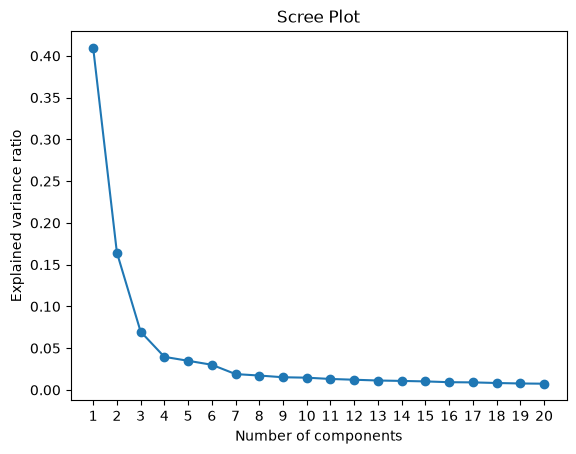

In [28]:
n_comps = np.arange(1,len(pca.explained_variance_ratio_)+1)
n_comps = [str(x) for x in n_comps]
plt.plot(n_comps[:20],pca.explained_variance_ratio_[:20],'-o')


plt.title('Scree Plot')
plt.xlabel('Number of components')
plt.ylabel('Explained variance ratio')

plt.show()

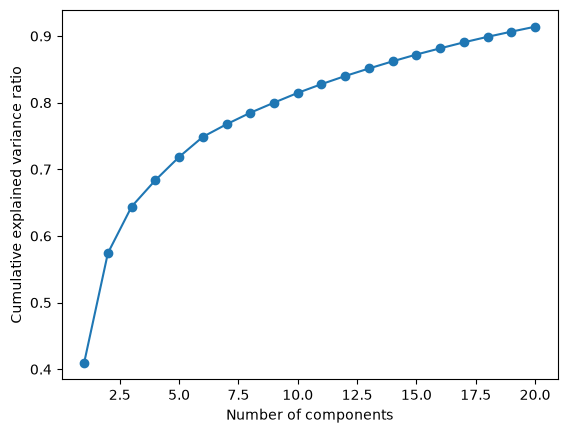

In [29]:
n_comps = np.arange(1, len(pca.explained_variance_ratio_) + 1)

cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

plt.plot(n_comps[:20], cumulative_variance[:20], "-o")

plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance ratio")
plt.show()

In [30]:
scores = pca.transform(line_profiles_wide.drop(columns=['systemlinenumber']))
print(scores.shape)

(950, 51)


In [ ]:
def reconstruct_pca(pca, X, scores, k):
    """Reconstruct the original data using the first k principal components."""

    if k == 0:
        # With no components, every participant receives the average music profile
        recon = np.tile(pca.mean_, (X.shape[0], 1))

    else:
        # Reconstruct using the first k components
        recon = scores[:, :k] @ pca.components_[:k, :] + pca.mean_

    return pd.DataFrame(recon, columns=X.columns, index=X.index)


# Calculate and store the reconstructions
df_reconstructions = {}

for k in range(pca.n_components_ + 1):

    df_reconstructions[k] = reconstruct_pca(pca, line_profiles_wide.drop(columns=['systemlinenumber']), scores, k)

    # Calculate reconstruction error
    mse_k = np.mean(
        (line_profiles_wide.drop(columns=['systemlinenumber']).values - df_reconstructions[k].values) ** 2
    )

    print(f"k={k}: reconstruction MSE={mse_k:.6f}")

In [34]:
df_scores = pd.DataFrame(
    scores,
    columns=[f"PC{i+1}" for i in range(scores.shape[1])],
    index=line_profiles_wide.drop(columns=['systemlinenumber']).index
)

# Display only the first 6 components
display(df_scores.iloc[:, :6].head())

,PC1,PC2,PC3,PC4,PC5,PC6
0,0.390158,0.463271,0.198453,0.039303,0.068197,-0.155391
1,-0.021212,0.533478,0.075245,-0.017554,-0.008081,-0.159188
2,0.398662,0.561681,0.399447,0.006955,-0.008237,-0.300028
3,-0.197657,0.541709,-0.142800,-0.097100,0.027157,-0.161016
4,0.392311,0.777562,-0.053324,0.160096,-0.216362,-0.116639


In [35]:
df_reconstructions[51].head()

,weekdaytype_0_hour_0,weekdaytype_0_hour_1,weekdaytype_0_hour_2,weekdaytype_0_hour_3,weekdaytype_0_hour_4,weekdaytype_0_hour_5,weekdaytype_0_hour_6,weekdaytype_0_hour_7,weekdaytype_0_hour_8,weekdaytype_0_hour_9,...,weekdaytype_1_hour_17,weekdaytype_1_hour_18,weekdaytype_1_hour_19,weekdaytype_1_hour_20,weekdaytype_1_hour_21,weekdaytype_1_hour_22,weekdaytype_1_hour_23,weekdaytype_ratio_hour_8,weekdaytype_ratio_hour_17,weekend_to_workday_ratio
0,6.725605e-02,7.866304e-02,6.719958e-03,1.387779e-17,2.046974e-16,0.030358,0.270415,1.000000,0.612720,0.209417,...,0.297101,0.305639,0.187684,1.712403e-01,8.427618e-02,1.172450e-01,2.810300e-02,0.019242,0.007185,0.002657
1,6.092692e-02,1.627424e-02,4.393768e-04,1.491862e-16,1.994932e-16,0.059279,0.256136,1.000000,0.392558,0.270079,...,0.180437,0.173671,0.151253,4.822296e-02,9.286718e-02,7.807091e-02,1.807722e-02,0.024572,0.008040,0.001850
2,1.318390e-16,-2.775558e-16,-2.220446e-16,-2.081668e-17,3.105155e-16,0.058371,0.252982,1.000000,0.646558,0.292295,...,0.301287,0.314908,0.243729,1.852874e-01,1.562291e-01,1.774543e-01,1.665335e-16,0.022284,0.008898,0.002308
3,1.179612e-16,-1.873501e-16,3.469447e-17,2.532696e-16,1.162265e-16,0.071100,0.464321,1.000000,0.366864,0.222354,...,0.149649,0.140675,0.087571,-2.081668e-16,-1.387779e-17,-1.387779e-17,4.163336e-17,0.017712,0.005411,0.001356
4,-6.938894e-18,-1.526557e-16,5.475136e-02,8.673617e-17,1.647987e-16,0.048356,0.325576,0.750296,0.827541,0.183503,...,0.226144,0.220690,0.199632,1.297186e-01,1.015006e-01,9.363886e-02,2.498002e-16,0.053722,0.008433,0.001509


In [38]:
feature_columns=line_profiles_wide.drop(columns=['systemlinenumber']).columns
df = pd.DataFrame(pca.components_.transpose(),
                  columns = [f'PC_{i+1}' for i in range(len(feature_columns))],
                  index=feature_columns)
df

,PC_1,PC_2,PC_3,PC_4,PC_5,PC_6,PC_7,PC_8,PC_9,PC_10,...,PC_42,PC_43,PC_44,PC_45,PC_46,PC_47,PC_48,PC_49,PC_50,PC_51
weekdaytype_0_hour_0,-0.031115,-0.021452,0.095606,0.051576,-0.097556,0.066702,-0.064213,-0.051703,0.258742,-0.105382,...,0.020395,-0.097798,0.046754,-0.045339,-0.042717,-0.016045,0.005025,0.055223,-0.007232,0.000760
weekdaytype_0_hour_1,-0.041894,-0.021644,0.051611,0.270113,0.083593,0.142586,-0.039079,0.101662,0.100297,0.015383,...,-0.004444,0.101197,-0.465487,0.019880,0.154527,-0.016482,0.001998,-0.085976,-0.000237,-0.005891
weekdaytype_0_hour_2,-0.040342,-0.018148,0.027257,0.240919,0.094324,0.103814,-0.019603,0.098732,-0.064615,0.063569,...,-0.015213,-0.085445,0.629994,0.007932,-0.388459,0.045583,0.002011,-0.294772,0.016603,-0.011877
weekdaytype_0_hour_3,-0.020201,-0.009627,0.013000,0.120347,0.048200,0.051370,-0.006162,0.044620,-0.048145,0.034732,...,-0.009842,0.009308,0.284738,0.072836,0.168897,-0.056606,-0.007137,0.794570,-0.024110,0.010738
weekdaytype_0_hour_4,-0.006555,-0.005742,0.012039,0.017826,-0.000443,0.021000,0.042062,0.004649,-0.061540,0.005539,...,-0.023400,-0.082599,0.341412,0.067244,0.649237,-0.107137,0.013941,-0.213546,0.001415,-0.002609
weekdaytype_0_hour_5,0.032398,0.040906,0.079837,0.028819,-0.010141,0.003442,0.009503,-0.022788,-0.086259,-0.042637,...,0.230943,-0.107386,-0.090040,0.005080,-0.070904,-0.286500,-0.018437,0.011315,0.006823,-0.004938
weekdaytype_0_hour_6,0.163866,0.236180,0.232426,0.077848,0.076514,-0.132418,-0.105849,-0.312495,-0.153592,-0.302634,...,-0.055109,-0.031733,-0.003945,0.036613,0.000644,0.068076,0.012334,0.002736,0.012329,-0.003532
weekdaytype_0_hour_7,0.219213,0.466132,0.053440,-0.260103,0.323172,0.079798,0.018892,0.193121,0.417583,0.412787,...,-0.013449,0.024050,0.015096,-0.014361,0.004623,0.004421,-0.005966,-0.005526,-0.006102,0.011311
weekdaytype_0_hour_8,0.176234,0.098484,-0.093560,0.127518,-0.205695,-0.294817,0.120211,0.563379,0.036782,-0.372341,...,-0.005978,0.008671,0.006806,0.005611,0.007070,-0.000337,0.007623,-0.003037,-0.025749,0.017434
weekdaytype_0_hour_9,0.182638,-0.067689,-0.158024,0.162974,-0.241006,-0.076122,-0.184345,0.022602,0.004907,0.173079,...,0.127342,-0.027399,-0.016937,0.041241,-0.004238,0.016556,0.009109,0.006905,0.000517,0.004310


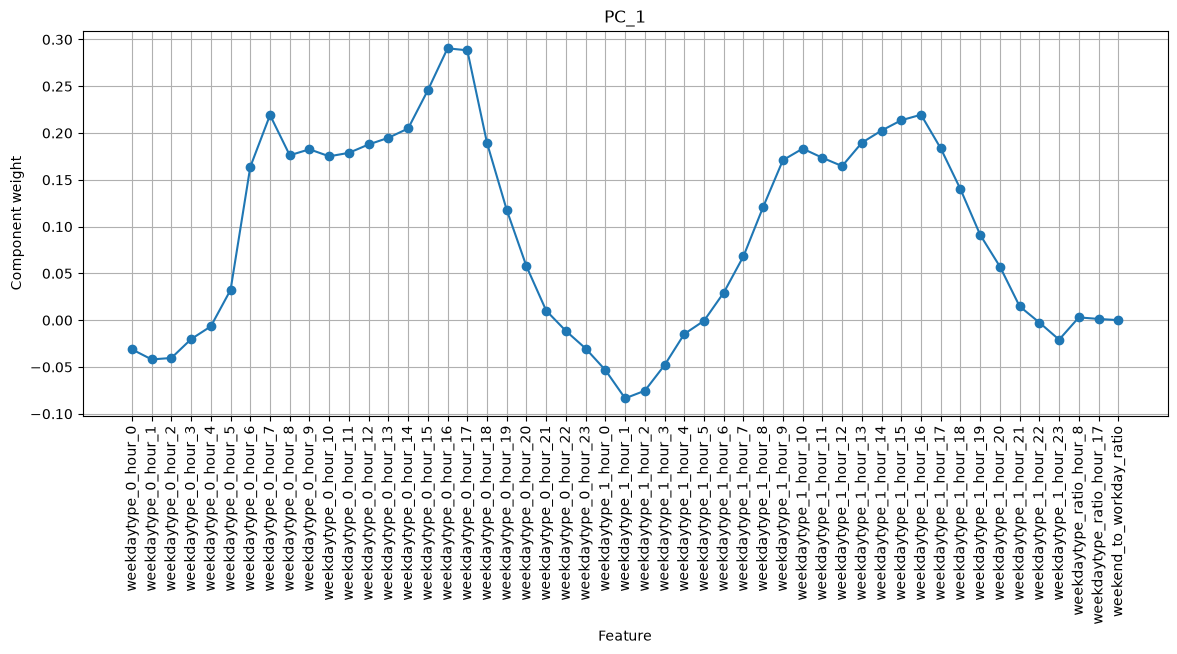

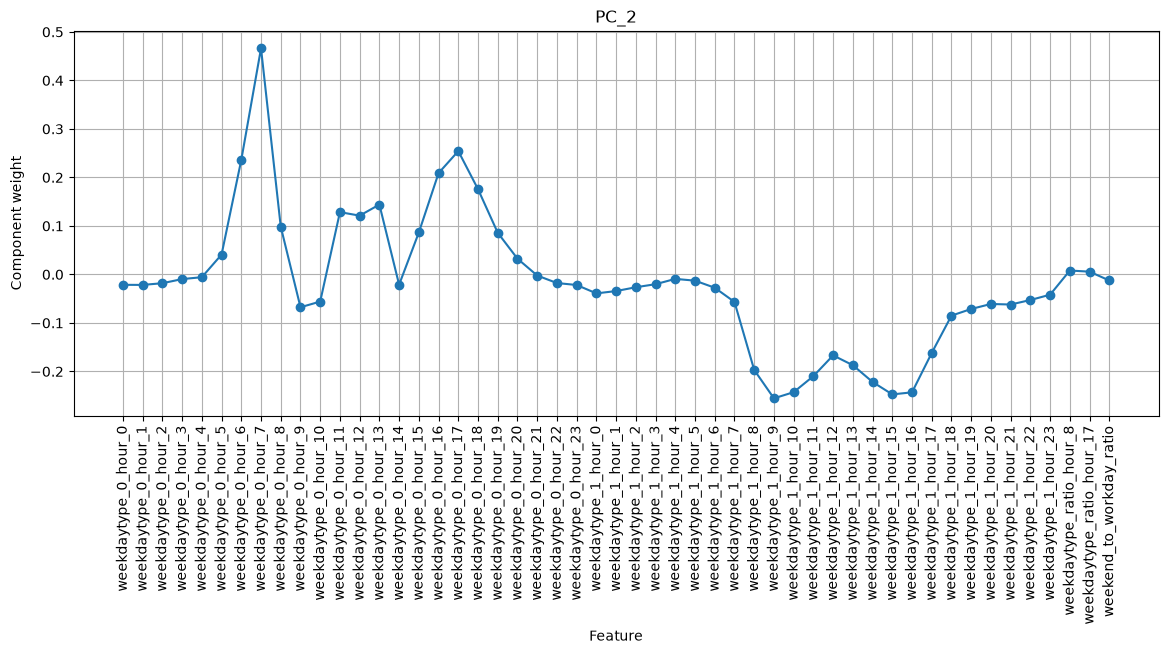

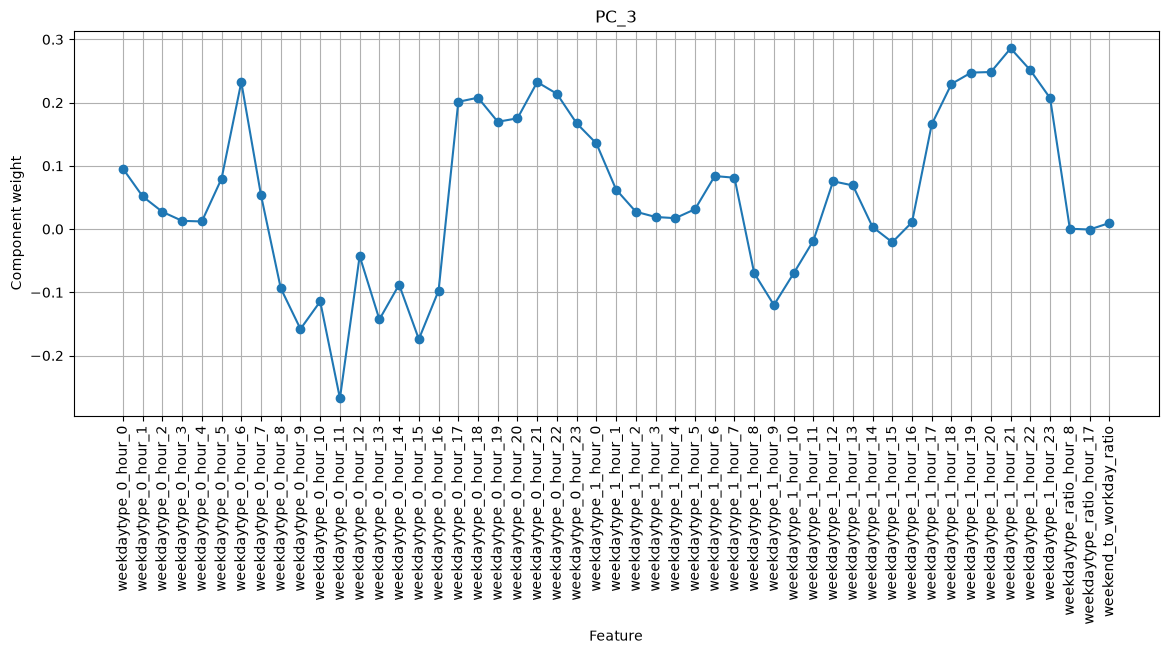

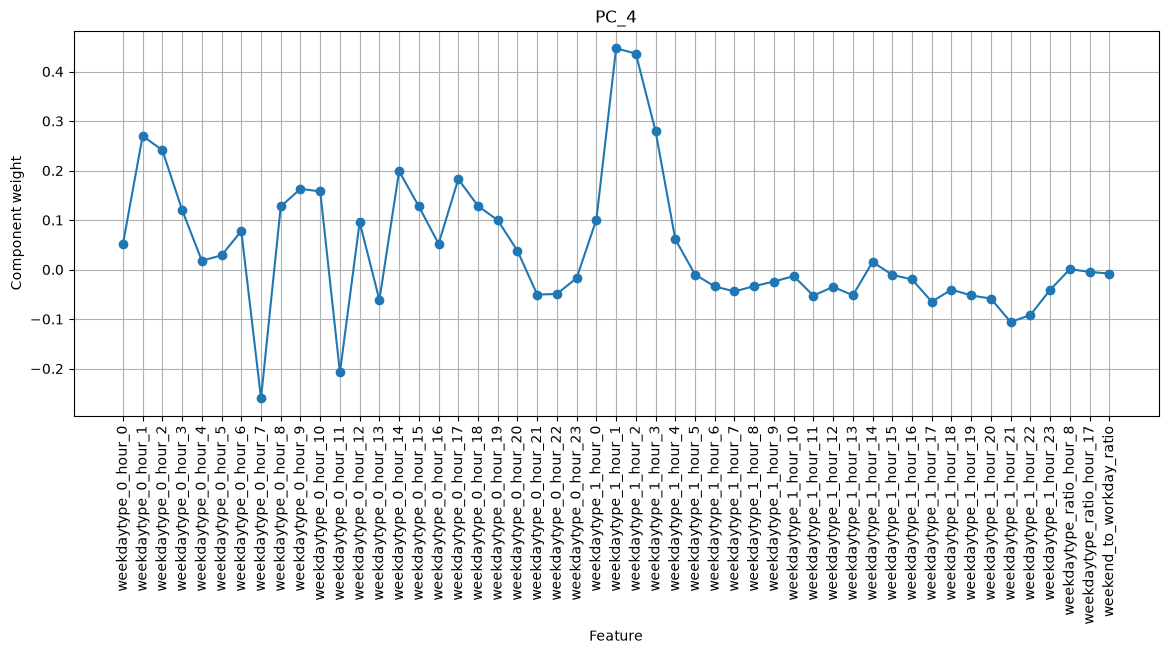

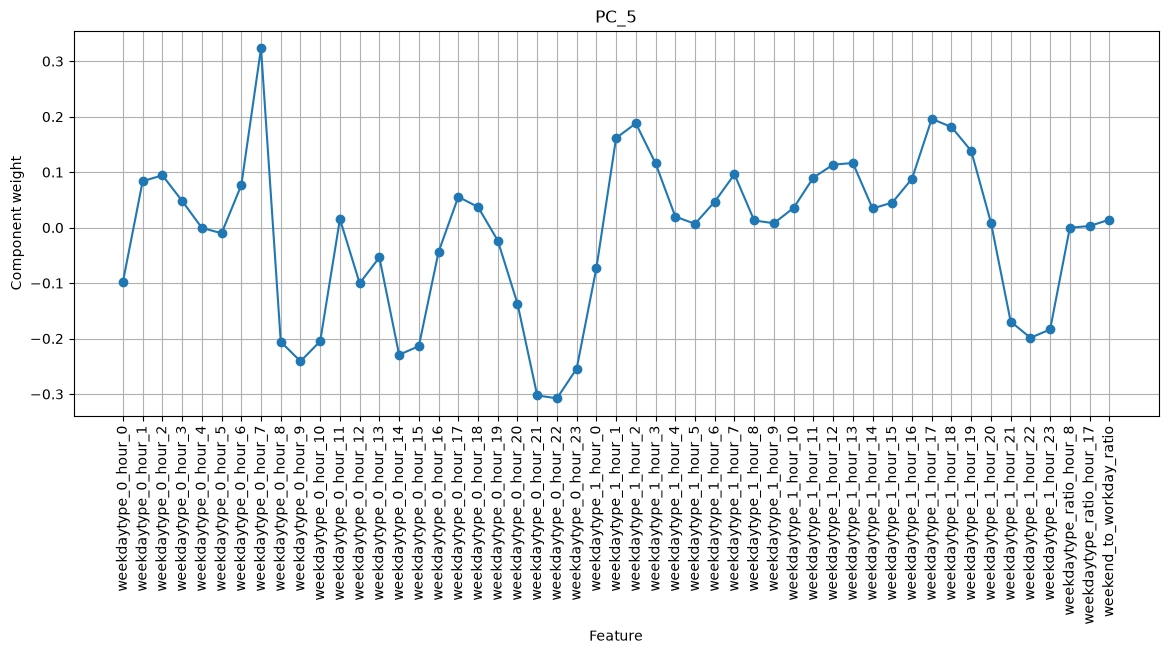

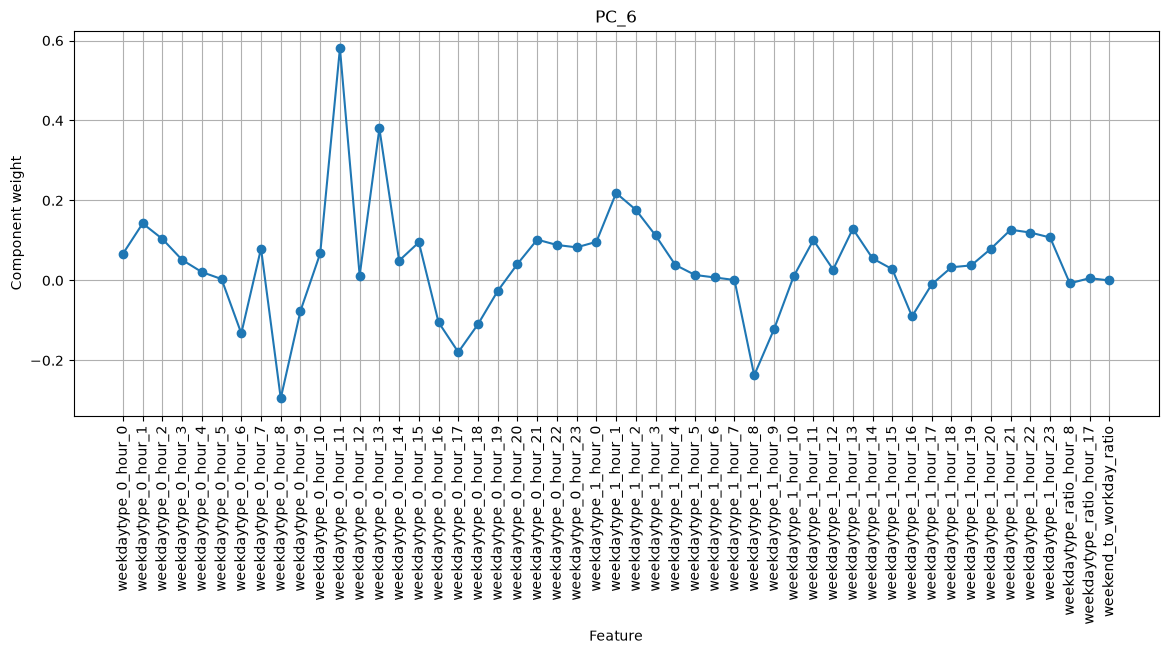

In [40]:
for vector in ['PC_1', 'PC_2', 'PC_3', 'PC_4', 'PC_5', 'PC_6']:
    plt.figure(figsize=(14, 5))
    plt.title(vector)
    plt.plot(np.arange(len(feature_columns)), df[vector], '-o')
    plt.xticks(np.arange(len(feature_columns)), feature_columns, rotation=90)
    plt.xlabel("Feature")
    plt.ylabel("Component weight")
    plt.grid()
    plt.show()

## 4. Clustering using UMAP and HDBSCAN
Next, **UMAP** is applied to the data set, this is a nonlinear dimensionality-reduction method.

c:\Users\schue\Documents\Sonstiges\CAS_Data_Science\CAS-ADS-2026-Projects\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


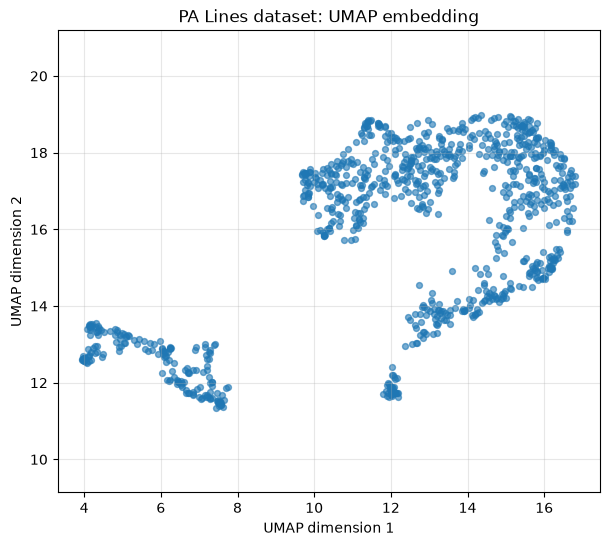

In [42]:
umap_model = umap.UMAP(n_neighbors=30, n_components=2, random_state=1711)
# umap_model = umap.UMAP(n_neighbors=20, n_components=2, random_state=1711, n_jobs=1)

umap_pa_lines = umap_model.fit_transform(line_profiles_wide.drop(columns=['systemlinenumber']))

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(umap_pa_lines[:, 0], umap_pa_lines[:, 1], s=18, alpha=0.6)

ax.set(
    title="PA Lines dataset: UMAP embedding",
    xlabel="UMAP dimension 1",
    ylabel="UMAP dimension 2",
)
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

plt.show()

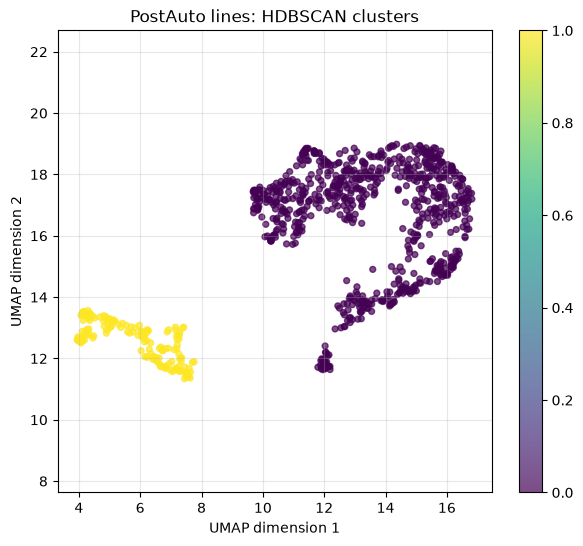

In [49]:
clusterer = hdbscan.HDBSCAN(min_cluster_size=20, gen_min_span_tree=True)
clusterer.fit(umap_pa_lines)

labels = clusterer.labels_
classes = set(labels) - {-1}  # -1 indicates noise (unassigned lines)

fig, ax = plt.subplots(figsize=(7, 6))

scatter = ax.scatter(
    umap_pa_lines[:, 0],
    umap_pa_lines[:, 1],
    c=labels,
    cmap="viridis",
    s=18,
    alpha=0.7,
)

ax.set(
    title="PostAuto lines: HDBSCAN clusters",
    xlabel="UMAP dimension 1",
    ylabel="UMAP dimension 2",
)
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

colorbar = fig.colorbar(scatter, ax=ax)

plt.show()

Very nicely, there appear **two clusters**. Are they the commuter (e.g. lines 701/709) and the touristic (e.g. 651/2601) line clusters...?

In [50]:
cluster_labels = clusterer.fit_predict(umap_pa_lines)

clustered_data = pd.DataFrame({
    "linenumbers": line_profiles_wide["systemlinenumber"],
    "cluster": cluster_labels
})

print(clustered_data["cluster"].value_counts().sort_index())
clustered_data.groupby("cluster").head(5).sort_values("cluster")

cluster
0    772
1    178
Name: count, dtype: int64


,linenumbers,cluster
0,11,0
1,20,0
2,30,0
3,31,0
4,32,0
69,344,1
71,346,1
72,348,1
85,370,1
86,371,1


In [51]:
clustered_data[clustered_data["linenumbers"].isin([2601,651,701,709])]  # Example to check a specific line number's cluster assignment

,linenumbers,cluster
165,651,0
189,701,0
197,709,0
593,2601,0


Unfortunately not...
But what are they, then? Let's randomly pick two lines, one from each cluster to check what their profiles look like.

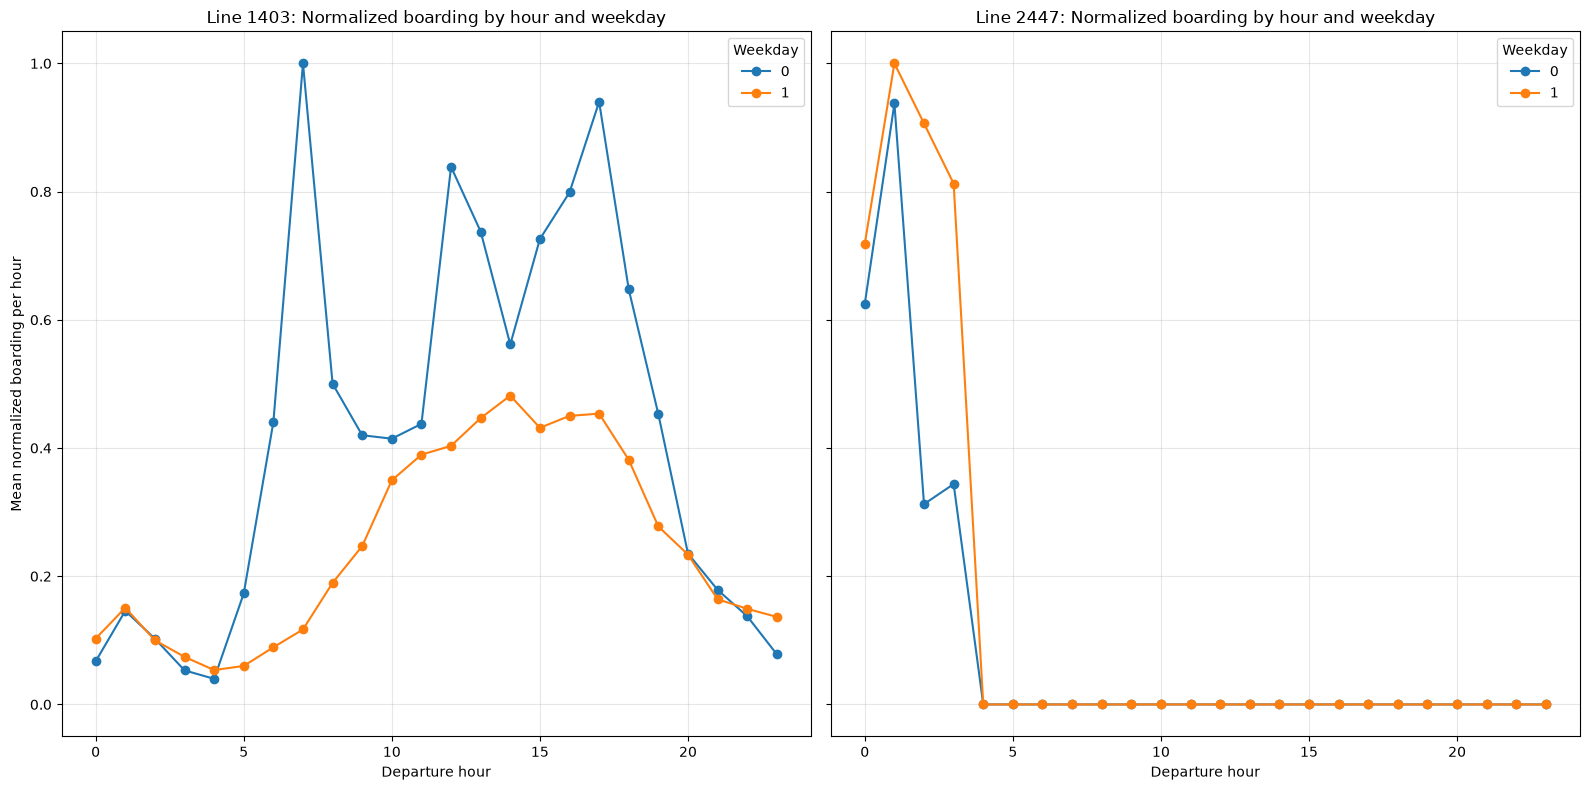

In [52]:
line_numbers = (#[701,709, 2601, 651]
    clustered_data
    .groupby("cluster", group_keys=False)
    .sample(n=1, random_state=5)
)["linenumbers"] # = [32,429, 2601, 651]
# line_numbers = (clustered_data[clustered_data["cluster"] == 1].sample(n=4, random_state=42))["linenumbers"]
fig, axes = plt.subplots(round(len(line_numbers)/2), 2, figsize=(16, 8), sharex=True, sharey=True)

for ax, line_number in zip(axes.flat, line_numbers):
    line_data = line_profiles[
        line_profiles["systemlinenumber"] == line_number
    ]

    plot_data = (
        line_data
        .pivot_table(
            index="departurecet_h",
            columns="weekday_nr",
            values="normalized_boarding",
            aggfunc="mean",
        )
        .sort_index()
    )

    plot_data.plot(
        ax=ax,
        marker="o",
    )

    ax.set(
        title=f"Line {line_number}: Normalized boarding by hour and weekday",
        xlabel="Departure hour",
        ylabel="Mean normalized boarding per hour",
    )
    ax.legend(title="Weekday")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

From that clustering it can be seen that special lines, such as night lines, weekend-only lines and workday-only lines are separated from the lines running more regularly. Thus, these special lines are removed from the data set, and the clustering is applied again in the cleaned data set.

In [53]:
filtered_lines = (clustered_data[clustered_data["cluster"].isin([0])])["linenumbers"]
filtered_line_profiles_wide = line_profiles_wide[line_profiles_wide["systemlinenumber"].isin(filtered_lines)]

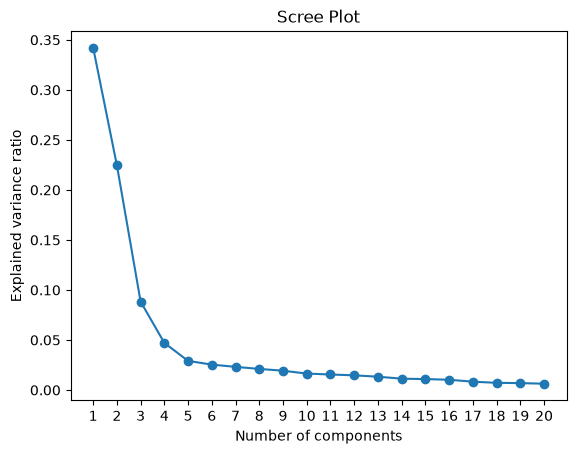

In [54]:
pca=PCA()
pca.fit(filtered_line_profiles_wide.drop(columns=['systemlinenumber']))

n_comps = np.arange(1,len(pca.explained_variance_ratio_)+1)
n_comps = [str(x) for x in n_comps]
plt.plot(n_comps[:20],pca.explained_variance_ratio_[:20],'-o')


plt.title('Scree Plot')
plt.xlabel('Number of components')
plt.ylabel('Explained variance ratio')

plt.show()

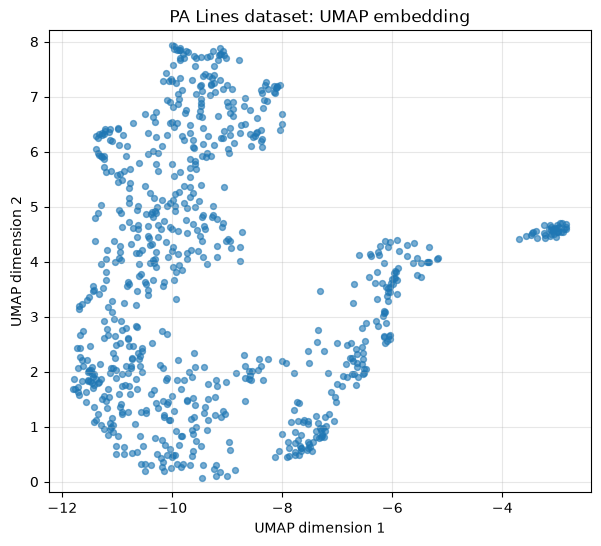

In [55]:
#umap_model = umap.UMAP(n_neighbors=30, n_components=2, random_state=1711)
# umap_model = umap.UMAP(n_neighbors=20, n_components=2, random_state=1711, n_jobs=1)

umap_pa_lines = umap_model.fit_transform(filtered_line_profiles_wide.drop(columns=['systemlinenumber']))

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(umap_pa_lines[:, 0], umap_pa_lines[:, 1], s=18, alpha=0.6)

ax.set(
    title="PA Lines dataset: UMAP embedding",
    xlabel="UMAP dimension 1",
    ylabel="UMAP dimension 2",
)
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

plt.show()

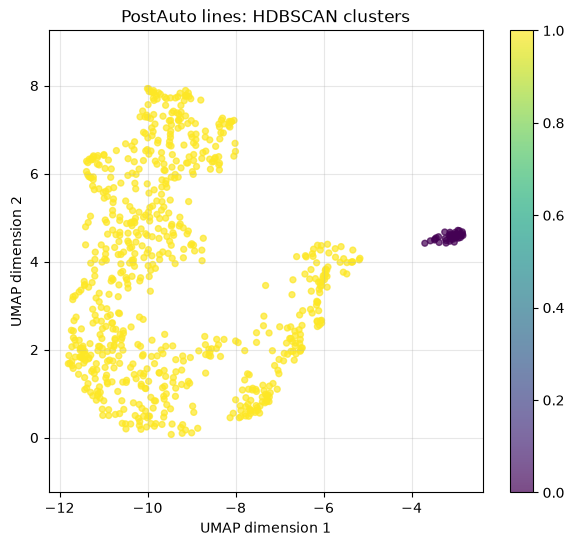

In [56]:
clusterer = hdbscan.HDBSCAN(min_cluster_size=20, gen_min_span_tree=True)
clusterer.fit(umap_pa_lines)

labels = clusterer.labels_
classes = set(labels) - {-1}  # -1 indicates noise (unassigned lines)

fig, ax = plt.subplots(figsize=(7, 6))

scatter = ax.scatter(
    umap_pa_lines[:, 0],
    umap_pa_lines[:, 1],
    c=labels,
    cmap="viridis",
    s=18,
    alpha=0.7,
)

ax.set(
    title="PostAuto lines: HDBSCAN clusters",
    xlabel="UMAP dimension 1",
    ylabel="UMAP dimension 2",
)
ax.set_aspect("equal", adjustable="datalim")
ax.grid(alpha=0.3)

colorbar = fig.colorbar(scatter, ax=ax)

plt.show()

In [57]:
cluster_labels = clusterer.fit_predict(umap_pa_lines)

clustered_data = pd.DataFrame({
    "linenumbers": filtered_line_profiles_wide["systemlinenumber"],
    "cluster": cluster_labels
})

print(clustered_data["cluster"].value_counts().sort_index())
clustered_data.groupby("cluster").head(5).sort_values("cluster")

cluster
0     37
1    735
Name: count, dtype: int64


,linenumbers,cluster
316,1235,0
451,1732,0
132,429,0
660,2769,0
826,4046,0
2,30,1
3,31,1
0,11,1
4,32,1
1,20,1


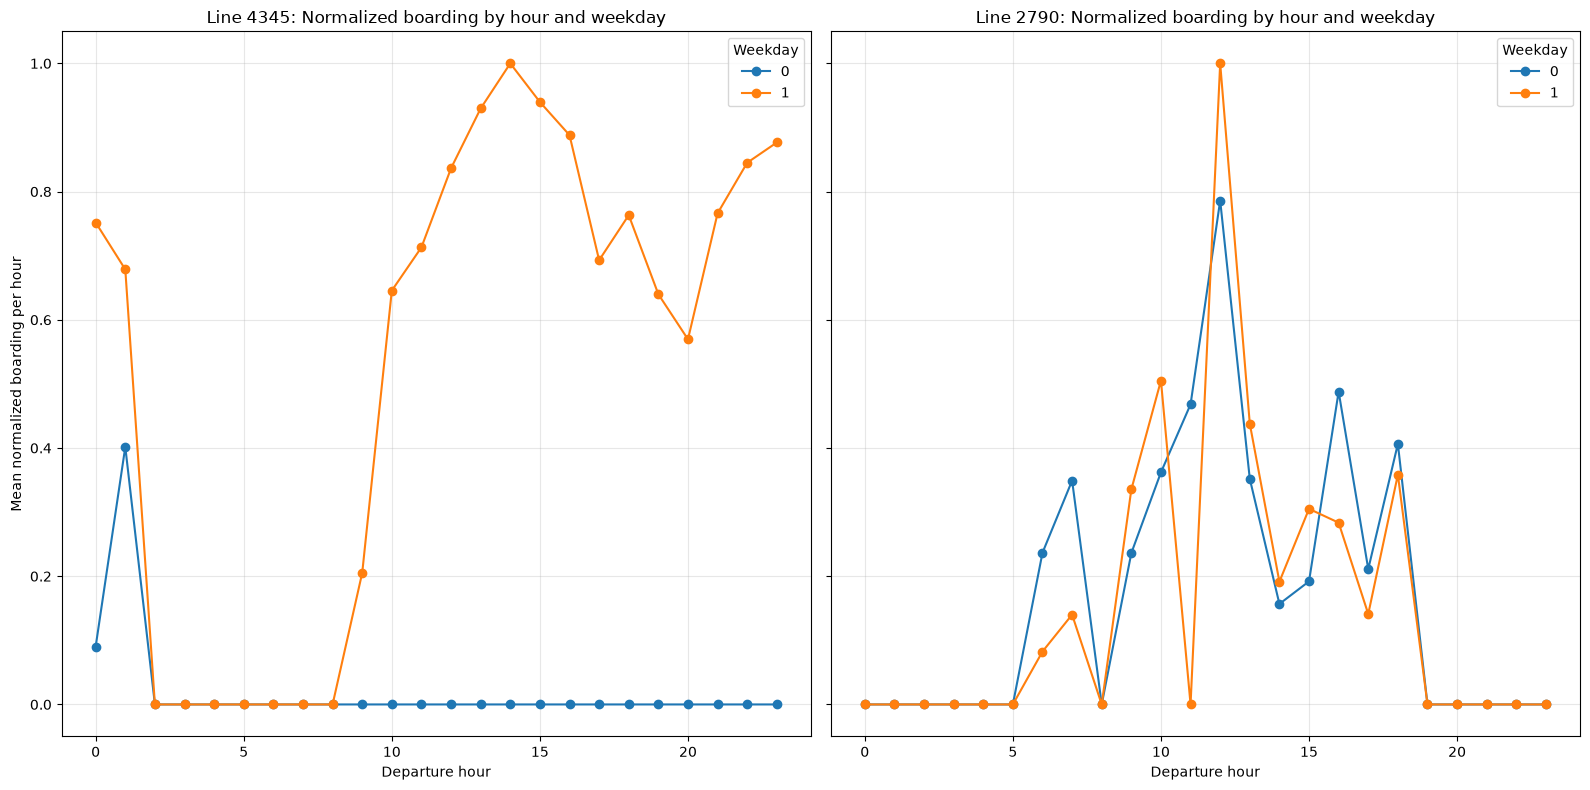

In [58]:
line_numbers = (#[701,709, 2601, 651]
    clustered_data
    .groupby("cluster", group_keys=False)
    .sample(n=1, random_state=42)
)["linenumbers"] # = [32,429, 2601, 651]
# line_numbers = (clustered_data[clustered_data["cluster"] == 1].sample(n=4, random_state=42))["linenumbers"]
fig, axes = plt.subplots(round(len(line_numbers)/2), 2, figsize=(16, 8), sharex=True, sharey=True)

for ax, line_number in zip(axes.flat, line_numbers):
    line_data = line_profiles[
        line_profiles["systemlinenumber"] == line_number
    ]

    plot_data = (
        line_data
        .pivot_table(
            index="departurecet_h",
            columns="weekday_nr",
            values="normalized_boarding",
            aggfunc="mean",
        )
        .sort_index()
    )

    plot_data.plot(
        ax=ax,
        marker="o",
    )

    ax.set(
        title=f"Line {line_number}: Normalized boarding by hour and weekday",
        xlabel="Departure hour",
        ylabel="Mean normalized boarding per hour",
    )
    ax.legend(title="Weekday")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Next, I try to cluster directly on the line profiles, without umap.

Maybe, the clustering results in different groups of lines?

In [59]:
features = line_profiles_wide.drop(columns="systemlinenumber")

clusterer = hdbscan.HDBSCAN(min_cluster_size=20)
labels = clusterer.fit_predict(features)

clustered_data = pd.DataFrame({
    "linenumbers": line_profiles_wide["systemlinenumber"],
    "cluster": labels,
})

print(clustered_data["cluster"].value_counts().sort_index())
clustered_data.groupby("cluster").head(5).sort_values("cluster")

cluster
-1    280
 0     29
 1    554
 2     87
Name: count, dtype: int64


,linenumbers,cluster
56,238,-1
69,344,-1
30,161,-1
72,348,-1
73,349,-1
660,2769,0
827,4047,0
826,4046,0
830,4051,0
829,4050,0


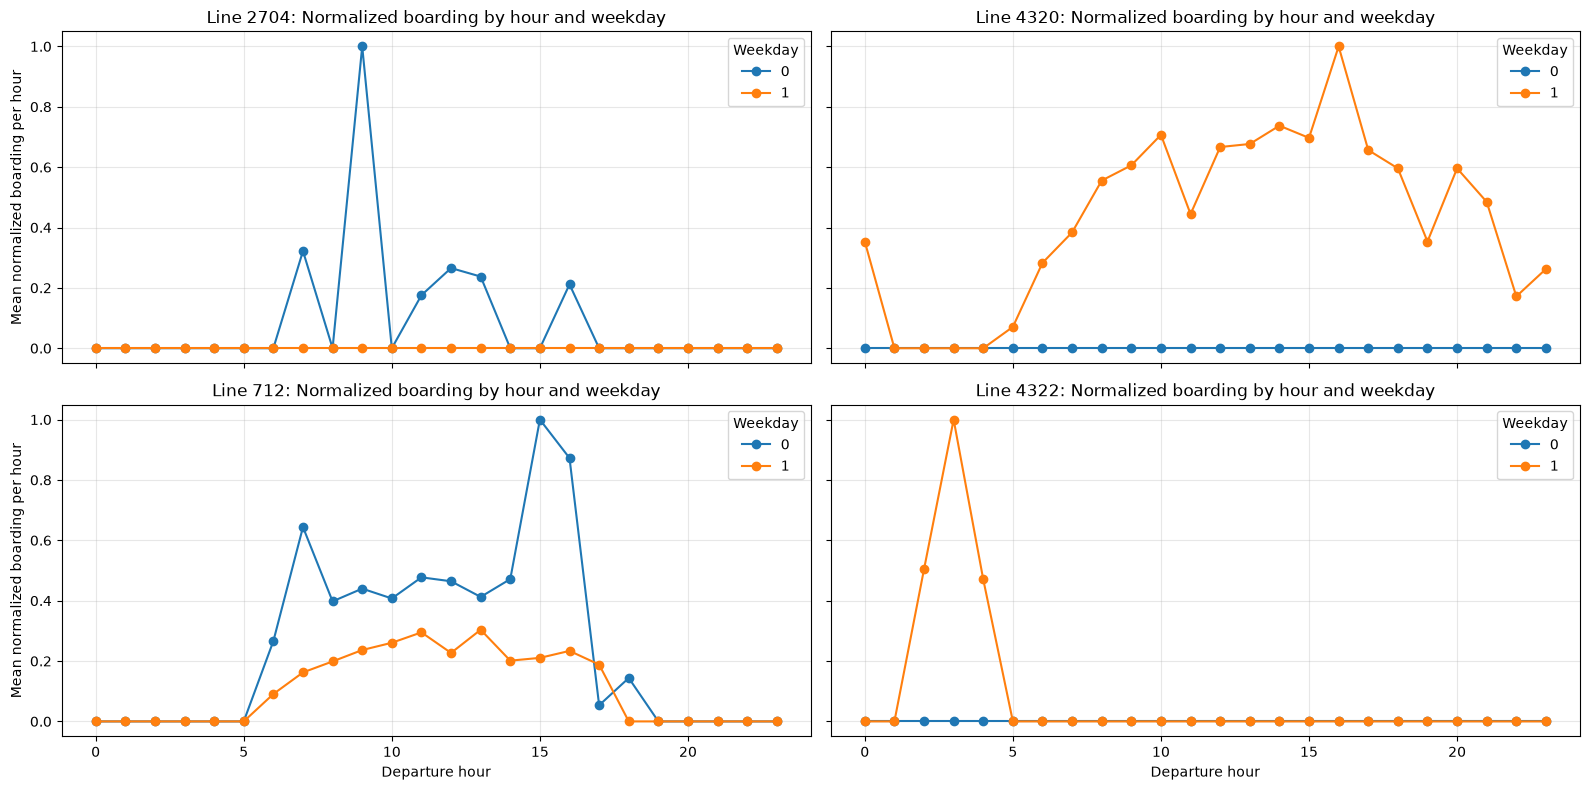

In [61]:
line_numbers = (#[701,709, 2601, 651]
    clustered_data
    .groupby("cluster", group_keys=False)
    .sample(n=1, random_state=21)
)["linenumbers"] # = [32,429, 2601, 651]
# line_numbers = (clustered_data[clustered_data["cluster"] == 1].sample(n=6, random_state=12))["linenumbers"]
fig, axes = plt.subplots(round(len(line_numbers)/2), 2, figsize=(16, 8), sharex=True, sharey=True)

for ax, line_number in zip(axes.flat, line_numbers):
    line_data = line_profiles[
        line_profiles["systemlinenumber"] == line_number
    ]

    plot_data = (
        line_data
        .pivot_table(
            index="departurecet_h",
            columns="weekday_nr",
            values="normalized_boarding",
            aggfunc="mean",
        )
        .sort_index()
    )

    plot_data.plot(
        ax=ax,
        marker="o",
    )

    ax.set(
        title=f"Line {line_number}: Normalized boarding by hour and weekday",
        xlabel="Departure hour",
        ylabel="Mean normalized boarding per hour",
    )
    ax.legend(title="Weekday")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusion

Feature engineering matters!

It is most important to get useful and reasonable results.

It is very time consuming (and at my stage a lot of try-and-error...).

I run out of time to do some further feature engineering. I wanted to do some regression and nn, too.